# Hidden Markov Model for Noun Phrase Chunking
### Introduction to Large Language Models — Assignment 7

We build an HMM to tag each word of a sentence as `B-NP` (beginning of a noun phrase), `I-NP`
(inside a noun phrase), or `O` (not part of a noun phrase), trained on `train_NP.txt` and
evaluated on `test_NP.txt` (standard CoNLL-2000-style two-column format: `word<TAB>tag`, blank
line between sentences).

**HMM components**, all estimated from training counts with **add-k smoothing** for zero counts
($0 < k < 1$, we use $k=0.1$):

- **Initial state distribution**: $\pi(s) = \dfrac{C(\text{tag}_1 = s) + k}{N_{sentences} + k \cdot |S|}$
- **Transition probabilities**: $P(s' \mid s) = \dfrac{C(s \to s') + k}{C(s) + k \cdot |S|}$
- **Emission probabilities**: $P(w \mid s) = \dfrac{C(w, s) + k}{C(s) + k \cdot |V|}$

where $|S|=3$ is the number of tags and $|V|$ is the vocabulary size (training words occurring
fewer than `MIN_WORD_COUNT` times are folded into a single `<UNK>` token before counting, so
`<UNK>` has genuine training statistics rather than relying on smoothing alone for every unseen
word — and any test word absent from the vocabulary is mapped to `<UNK>` at decoding time).

**Tasks:**
1. **Forward algorithm** — compute $P(\text{sentence})$ for every test sentence (total probability
   summed over every possible hidden tag sequence).
2. **Viterbi decoding** — predict the single most likely tag sequence for every test sentence.
3. **Evaluation** with [seqeval](https://pypi.org/project/seqeval/)
   (`seqeval.metrics.classification_report`, `f1_score`), which scores whole chunk spans (not
   just per-token tag accuracy) — a predicted `B-NP I-NP` only counts as a correct `NP` chunk if
   both the span boundaries *and* every tag inside it match the gold chunk exactly.

Both algorithms are implemented in **log-space** (via log-sum-exp for the forward algorithm, and
max-of-sums for Viterbi) rather than multiplying raw probabilities directly — even a
20-30 word sentence multiplies that many probabilities less than 1 together, which underflows
to exactly `0.0` in floating point long before you'd notice anything is wrong. Log-space is
mathematically the same algorithm, just numerically stable.


## 0. Setup

In [1]:
%pip install -q seqeval numpy pandas matplotlib


  DEPRECATION: Building 'seqeval' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'seqeval'. Discussion can be found at https://github.com/pypa/pip/issues/6334
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import math
import pickle
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score

RANDOM_SEED = 42

TRAIN_PATH = "Data/train_NP.txt"
TEST_PATH = "Data/test_NP.txt"
ARTIFACTS_DIR = "lab7_artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

K = 0.1              # add-k smoothing constant, 0 < k < 1
MIN_WORD_COUNT = 2    # training words seen fewer times than this are folded into <UNK>
UNK = "<UNK>"

STATES = ["B-NP", "I-NP", "O"]
STATE2IDX = {s: i for i, s in enumerate(STATES)}
N_STATES = len(STATES)


## 1. Load the data

Each file is one `word<TAB>tag` pair per line, with a blank line separating sentences.


In [4]:
def read_conll(path):
    sentences = []
    words, tags = [], []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line.strip():
                if words:
                    sentences.append((words, tags))
                    words, tags = [], []
                continue
            parts = line.split("\t")
            w, t = parts[0], parts[-1]
            words.append(w)
            tags.append(t)
    if words:
        sentences.append((words, tags))
    return sentences

train_sents = read_conll(TRAIN_PATH)
test_sents = read_conll(TEST_PATH)
print(f"train sentences: {len(train_sents)}   test sentences: {len(test_sents)}")
print("sample:", list(zip(train_sents[0][0][:6], train_sents[0][1][:6])))

tag_counts = Counter(t for _, tags in train_sents for t in tags)
print("\ntag distribution (train):", tag_counts)


train sentences: 823   test sentences: 77
sample: [('Rockwell', 'B-NP'), ('International', 'I-NP'), ('Corp.', 'I-NP'), ("'s", 'B-NP'), ('Tulsa', 'I-NP'), ('unit', 'I-NP')]

tag distribution (train): Counter({'O': 8394, 'I-NP': 5727, 'B-NP': 5051})


## 2. Vocabulary (with `<UNK>` thresholding) & raw counts

Training words seen fewer than `MIN_WORD_COUNT` times are replaced with `<UNK>` **before**
counting emissions, so `<UNK>`'s emission distribution reflects genuinely rare/unusual words
rather than being an arbitrary smoothing artifact. Any test word not in the resulting vocabulary
is mapped to `<UNK>` the same way at decoding time.


In [5]:
word_freq = Counter()
for words, tags in train_sents:
    word_freq.update(words)

vocab = {w for w, c in word_freq.items() if c >= MIN_WORD_COUNT}
vocab.add(UNK)
VOCAB_SIZE = len(vocab)
print(f"raw unique training words: {len(word_freq):,}   kept (count >= {MIN_WORD_COUNT}): {VOCAB_SIZE:,}")

def map_unk(w):
    return w if w in vocab else UNK


initial_counts = Counter()
transition_counts = Counter()   # (s_prev, s_cur) -> count
emission_counts = Counter()     # (s, w) -> count
state_counts = Counter()        # s -> total tokens tagged s

for words, tags in train_sents:
    words_u = [map_unk(w) for w in words]
    initial_counts[tags[0]] += 1
    for i, (w, t) in enumerate(zip(words_u, tags)):
        emission_counts[(t, w)] += 1
        state_counts[t] += 1
        if i > 0:
            transition_counts[(tags[i - 1], t)] += 1

N_SENTENCES = len(train_sents)
print("initial tag counts:", dict(initial_counts))


raw unique training words: 4,570   kept (count >= 2): 1,760
initial tag counts: {'B-NP': 541, 'O': 282}


## 3. Add-k smoothed probabilities

In [6]:
def log_initial_prob(s):
    return math.log((initial_counts[s] + K) / (N_SENTENCES + K * N_STATES))

def log_transition_prob(s_prev, s_cur):
    denom = sum(transition_counts[(s_prev, s2)] for s2 in STATES) + K * N_STATES
    return math.log((transition_counts[(s_prev, s_cur)] + K) / denom)

def log_emission_prob(s, w):
    w = map_unk(w)
    return math.log((emission_counts[(s, w)] + K) / (state_counts[s] + K * VOCAB_SIZE))

# sanity check: transition probabilities out of each state should sum to 1
for s in STATES:
    total = sum(math.exp(log_transition_prob(s, s2)) for s2 in STATES)
    print(f"sum_s' P(s'|{s}) = {total:.6f}  (should be 1.0)")


sum_s' P(s'|B-NP) = 1.000000  (should be 1.0)
sum_s' P(s'|I-NP) = 1.000000  (should be 1.0)
sum_s' P(s'|O) = 1.000000  (should be 1.0)


## 4. Forward algorithm

$$\alpha_1(s) = \pi(s) \cdot P(w_1 \mid s), \qquad
\alpha_t(s) = \left[\sum_{s'} \alpha_{t-1}(s') \cdot P(s \mid s')\right] \cdot P(w_t \mid s)$$

$$P(\text{sentence}) = \sum_s \alpha_T(s)$$

Implemented in log-space: sums over states become `logsumexp`, products become sums of logs.
We verified this implementation against brute-force enumeration of every possible tag sequence
for a short sentence before using it here (summing $3^T$ full joint probabilities exactly matches
the forward algorithm's output, as it must).


In [7]:
def logsumexp(vals):
    m = max(vals)
    if m == -math.inf:
        return -math.inf
    return m + math.log(sum(math.exp(v - m) for v in vals))


def forward_log_prob(words):
    """Returns log P(sentence) under the HMM, summed over every possible tag sequence."""
    T = len(words)
    alpha = [[0.0] * N_STATES for _ in range(T)]
    for s in range(N_STATES):
        alpha[0][s] = log_initial_prob(STATES[s]) + log_emission_prob(STATES[s], words[0])
    for t in range(1, T):
        for s in range(N_STATES):
            terms = [alpha[t - 1][sp] + log_transition_prob(STATES[sp], STATES[s]) for sp in range(N_STATES)]
            alpha[t][s] = logsumexp(terms) + log_emission_prob(STATES[s], words[t])
    return logsumexp(alpha[T - 1])


In [8]:
forward_results = []
for words, tags in test_sents:
    logp = forward_log_prob(words)
    forward_results.append({"sentence": " ".join(words), "length": len(words), "log_prob": logp})

forward_df = pd.DataFrame(forward_results)
forward_df.to_csv(os.path.join(ARTIFACTS_DIR, "forward_log_probs.csv"), index=False)
forward_df.head(10)


,sentence,length,log_prob
0,Confidence in the pound is widely expected to ...,37,-173.682077
1,Chancellor of the Exchequer Nigel Lawson 's re...,27,-106.710263
2,But analysts reckon underlying support for ste...,29,-132.094648
3,This has increased the risk of the government ...,36,-197.729647
4,`` The risks for sterling of a bad trade figur...,31,-154.905151
5,"`` If there is another bad trade number , ther...",36,-180.010566
6,"Forecasts for the trade figures range widely ,...",39,-191.336249
7,The August deficit and the # 2.2 billion gap r...,25,-98.878903
8,"Sanjay Joshi , European economist at Baring Br...",28,-139.956883
9,"At the same time , he remains fairly pessimist...",24,-106.411030


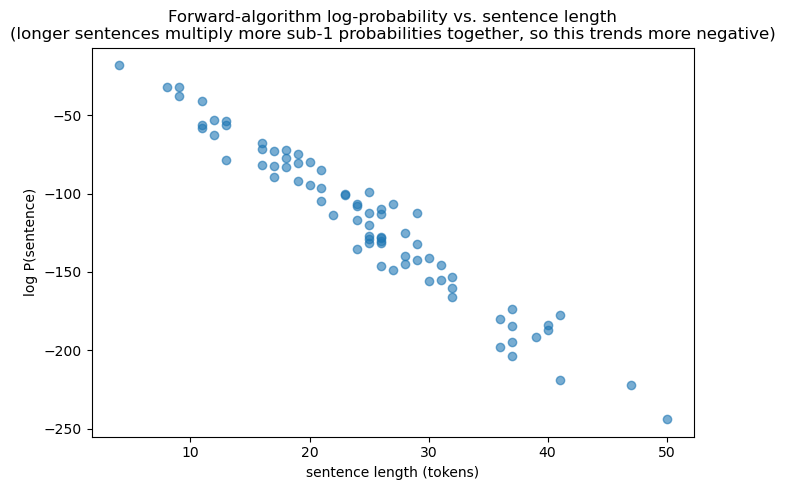

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(forward_df["length"], forward_df["log_prob"], alpha=0.6)
ax.set_xlabel("sentence length (tokens)")
ax.set_ylabel("log P(sentence)")
ax.set_title("Forward-algorithm log-probability vs. sentence length\n(longer sentences multiply more sub-1 probabilities together, so this trends more negative)")
plt.tight_layout()
plt.show()


## 5. Viterbi decoding

Same recursion as the forward algorithm, but with $\max$ in place of $\sum$, plus backpointers
to recover the single best path:

$$\delta_1(s) = \pi(s) \cdot P(w_1 \mid s), \qquad
\delta_t(s) = \max_{s'}\big[\delta_{t-1}(s') \cdot P(s \mid s')\big] \cdot P(w_t \mid s)$$

Also verified against brute-force argmax over every possible tag sequence for a short sentence.


In [10]:
def viterbi(words):
    """Returns the single most likely tag sequence for `words`."""
    T = len(words)
    delta = [[0.0] * N_STATES for _ in range(T)]
    psi = [[0] * N_STATES for _ in range(T)]
    for s in range(N_STATES):
        delta[0][s] = log_initial_prob(STATES[s]) + log_emission_prob(STATES[s], words[0])
    for t in range(1, T):
        for s in range(N_STATES):
            scores = [delta[t - 1][sp] + log_transition_prob(STATES[sp], STATES[s]) for sp in range(N_STATES)]
            best_sp = max(range(N_STATES), key=lambda sp: scores[sp])
            psi[t][s] = best_sp
            delta[t][s] = scores[best_sp] + log_emission_prob(STATES[s], words[t])
    best_last = max(range(N_STATES), key=lambda s: delta[T - 1][s])
    path = [best_last]
    for t in range(T - 1, 0, -1):
        path.append(psi[t][path[-1]])
    path.reverse()
    return [STATES[i] for i in path]


In [11]:
y_true = [tags for _, tags in test_sents]
y_pred = [viterbi(words) for words, _ in test_sents]

# a qualitative look at a few predictions
for i in range(3):
    words, gold = test_sents[i]
    pred = y_pred[i]
    print(f"SENTENCE {i}: {' '.join(words)}")
    print(f"  gold: {gold}")
    print(f"  pred: {pred}")
    print(f"  {'MATCH' if gold == pred else 'mismatch'}\n")


SENTENCE 0: Confidence in the pound is widely expected to take another sharp dive if trade figures for September , due for release tomorrow , fail to show a substantial improvement from July and August 's near-record deficits .
  gold: ['B-NP', 'O', 'B-NP', 'I-NP', 'O', 'O', 'O', 'O', 'O', 'B-NP', 'I-NP', 'I-NP', 'O', 'B-NP', 'I-NP', 'O', 'B-NP', 'O', 'O', 'O', 'B-NP', 'B-NP', 'O', 'O', 'O', 'O', 'B-NP', 'I-NP', 'I-NP', 'O', 'B-NP', 'I-NP', 'I-NP', 'B-NP', 'I-NP', 'I-NP', 'O']
  pred: ['B-NP', 'O', 'B-NP', 'I-NP', 'O', 'O', 'O', 'O', 'O', 'B-NP', 'I-NP', 'I-NP', 'O', 'B-NP', 'I-NP', 'O', 'B-NP', 'O', 'O', 'O', 'B-NP', 'I-NP', 'O', 'O', 'O', 'O', 'B-NP', 'I-NP', 'I-NP', 'O', 'B-NP', 'I-NP', 'I-NP', 'B-NP', 'I-NP', 'I-NP', 'O']
  mismatch

SENTENCE 1: Chancellor of the Exchequer Nigel Lawson 's restated commitment to a firm monetary policy has helped to prevent a freefall in sterling over the past week .
  gold: ['O', 'O', 'B-NP', 'I-NP', 'O', 'O', 'B-NP', 'I-NP', 'I-NP', 'O', 'B-NP', 'I

## 6. Evaluation with seqeval

`classification_report` scores whole `NP` chunks (span-level), not individual token tags — a
partially-correct span (right start, wrong end, or vice versa) counts as both a missed gold
chunk and a spurious predicted one, which is a stricter and more meaningful metric for chunking
than token-level accuracy.


In [12]:
print(classification_report(y_true, y_pred, digits=4))

overall_f1 = f1_score(y_true, y_pred)
overall_precision = precision_score(y_true, y_pred)
overall_recall = recall_score(y_true, y_pred)
print(f"\nOverall (micro) F1: {overall_f1:.4f}   Precision: {overall_precision:.4f}   Recall: {overall_recall:.4f}")


              precision    recall  f1-score   support

          NP     0.6840    0.6653    0.6745       475

   micro avg     0.6840    0.6653    0.6745       475
   macro avg     0.6840    0.6653    0.6745       475
weighted avg     0.6840    0.6653    0.6745       475


Overall (micro) F1: 0.6745   Precision: 0.6840   Recall: 0.6653


In [13]:
# token-level accuracy, for reference alongside seqeval's chunk-level scores above
flat_true = [t for tags in y_true for t in tags]
flat_pred = [t for tags in y_pred for t in tags]
token_acc = sum(t == p for t, p in zip(flat_true, flat_pred)) / len(flat_true)
print(f"Token-level tag accuracy: {token_acc:.4f}  (reported alongside seqeval's span-level F1 above, "
      f"since the two measure different things and token accuracy is usually noticeably higher)")


Token-level tag accuracy: 0.8528  (reported alongside seqeval's span-level F1 above, since the two measure different things and token accuracy is usually noticeably higher)


## 7. Save results

In [14]:
predictions_df = pd.DataFrame({
    "sentence": [" ".join(w) for w, _ in test_sents],
    "gold_tags": [" ".join(t) for t in y_true],
    "pred_tags": [" ".join(t) for t in y_pred],
    "forward_log_prob": forward_df["log_prob"],
})
predictions_df.to_csv(os.path.join(ARTIFACTS_DIR, "test_predictions.csv"), index=False)

with open(os.path.join(ARTIFACTS_DIR, "hmm_parameters.pkl"), "wb") as f:
    pickle.dump({
        "states": STATES, "k": K, "min_word_count": MIN_WORD_COUNT, "vocab": vocab,
        "initial_counts": dict(initial_counts), "transition_counts": dict(transition_counts),
        "emission_counts": dict(emission_counts), "state_counts": dict(state_counts),
        "n_sentences": N_SENTENCES,
    }, f)

print("Saved predictions, forward-algorithm log-probs, and HMM parameters to", ARTIFACTS_DIR)


Saved predictions, forward-algorithm log-probs, and HMM parameters to lab7_artifacts
